## Understanding liklihoods and priors for Zollman's "Epistemic Benefits of Transient diversity"

This paper uses the Bernoulli distribution for modeling the likelihood and the Beta distribution for modeling priors. 

Why Bernoulli? The Bernoulli distribution models a single experiment with boolean-valued outcomes. The results must be discrete and the distribution is normalized. An example might be a coin toss (boolean H/T outcome). An alternative to a Bernoulli distribution might be a binomial distribution. This would be appropriate if you only record the number of heads overall or the number of successes for clinical trials. Or, for other data types, the Poisson or normal distribution might be more appropriate.

Why Beta? Once you have chosen Bernoulli as your likelihood, you need to pick a prior. It is convenient to pick a prior that, when updated with the likelihood, will remain the same kind of distribution in the posterior. Or, put differently, the posterior remains in the same functional family as the prior. This is referred to as the conjugate prior for that likelihood. 

The beta distribution does this for the Bernoulli likelihood. When you update the beta distribution with the Bernoulli likelihood, it returns a beta kernel that is your posterior and is also a beta distribution. (Notably, the Beta distribution is also the conjugate prior for the Binomial probability mass function.) 

Note: when the phrase "conjugate prior" is used here, it just means "the matching prior"; there's no mathematical meaning to conjugate beyond that (i.e., no complex conjugation or anything of that sort is going on). Here, the Bernoulli and Beta distributions share the same functional form, making them conjugates. 
 
Beyond the nice feature of being a conjugate prior, the beta distribution has an intuitive motivation as being "a more flexible version of the uniform distribution" (see \S8.5 from A Student's Guide to Bayesian Statistics). For alpha, beta = 1,1, it recovers flat/uniform priors. 

References: 
- A Student's Guide to Bayesian Statistics https://sites.math.rutgers.edu/~zeilberg/EM20/Lambert.pdf
- https://en.wikipedia.org/wiki/Bernoulli_distribution  
- https://en.wikipedia.org/wiki/Beta_distribution
- https://en.wikipedia.org/wiki/Conjugate_prior 



Getting a handle on the Bernoulli probability density function. 

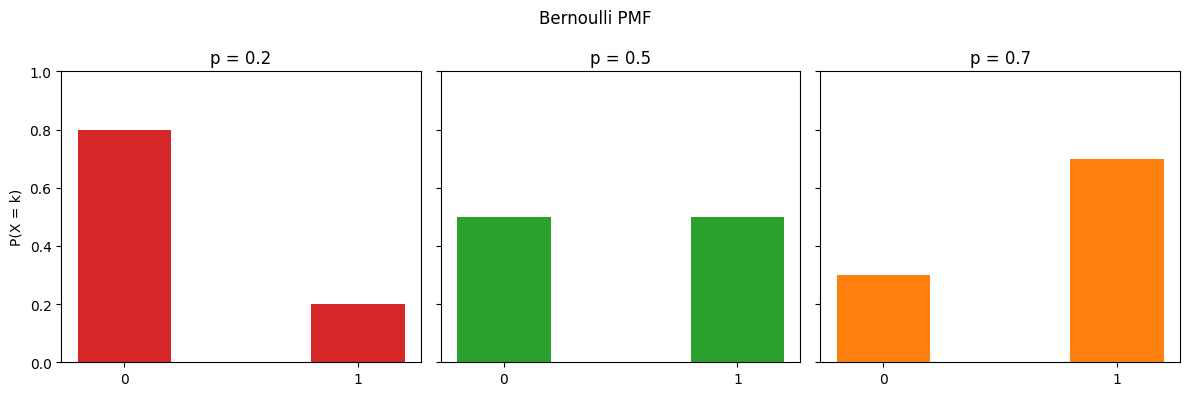

In [107]:
from scipy.stats import bernoulli
import numpy as np
import matplotlib.pyplot as plt
# biased coin (towards 0), fair coin, biased coin (towards 1) 
prob = [0.2, 0.5, 0.7]
colors = ["tab:red", "tab:green", "tab:orange"]
results = []
# Simulate 10 independent coin tosses
for round in prob: 
    tosses = (bernoulli.rvs(round, size=10))
    results.append(tosses)
xaxis = np.array([0,1])

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, p, c in zip(axes, prob, colors):
    ax.bar(xaxis, bernoulli.pmf(xaxis, p), width=0.4, color=c)
    ax.set_xticks(xaxis)
    ax.set_ylim(0, 1)
    ax.set_title(f"p = {p}")
axes[0].set_ylabel("P(X = k)")
fig.suptitle("Bernoulli PMF")
plt.tight_layout()
plt.show()

To get a handle on the beta distribution, we recreate the wiki figure of the beta distribution for different alpha, beta values. 
- figure: https://en.wikipedia.org/wiki/Beta_distribution

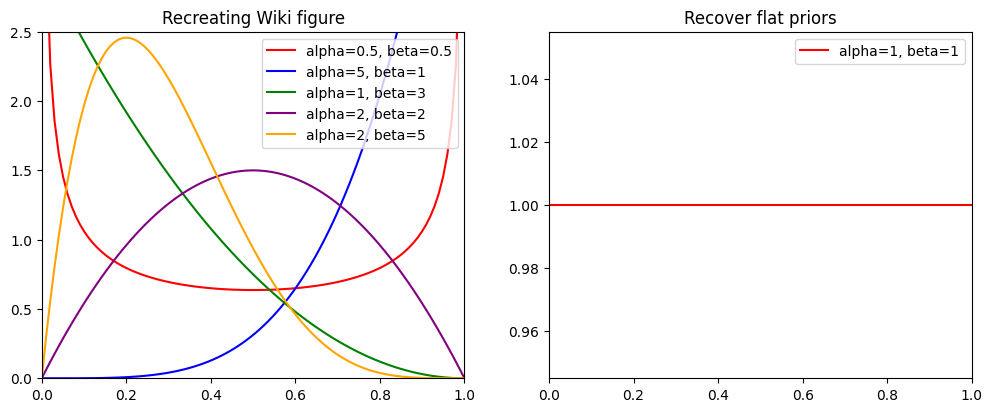

In [105]:
from scipy.stats import beta
import numpy as np
import matplotlib.pyplot as plt

alphavalue = [0.5, 5, 1, 2, 2]
betavalue = [0.5, 1, 3, 2, 5]
x = np.linspace(0, 1., 100)
priors = {}
for a, b in zip(alphavalue, betavalue):
    priors[(a, b)] = beta.pdf(x, a, b)
colors = ["red" , "blue", "green", "purple", "orange"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for prior in priors: 
    ax1.plot(x, priors[prior], color=colors[list(priors.keys()).index(prior)],  label=f"alpha={prior[0]}, beta={prior[1]}")
    ax1.set_xlim([0, 1])
    ax1.set_ylim([0,2.5])
    ax1.set_title("Recreating Wiki figure")
    ax1.legend()


alphavalueflat = [1]
betavalueflate = [1]
priorsflat = {}

for a, b in zip(alphavalueflat, betavalueflate):
    priorsflat[(a, b)] = beta.pdf(x, a, b)
colors = ["red" , "blue", "green", "purple", "orange"]
for prior in priorsflat: 
    ax2.plot(x, priorsflat[prior], color=colors[list(priorsflat.keys()).index(prior)], label=f"alpha={prior[0]}, beta={prior[1]}")
    ax2.set_xlim([0, 1])
    ax2.set_title("Recover flat priors")
    ax2.legend()
plt.show()


## Now we move to recreating Figure 1 in Zollman. 

The priors for a single agent initialized with random alpha and beta, each between 0, 4

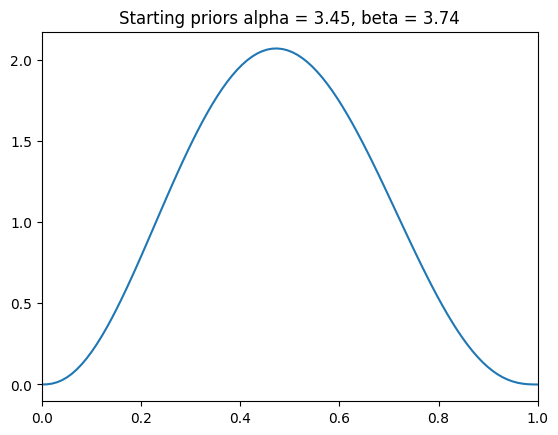

In [58]:
import random 
agentalpha = 4* random.random()
agentbeta =  4* random.random()
x = np.linspace(0, 1., 100)
agentpriors = beta.pdf(x, agentalpha, agentbeta)
plt.plot(x, agentpriors) 
plt.xlim([0, 1])
plt.title(f"Starting priors α = {agentalpha:.2f}, β = {agentbeta:.2f}")
plt.show()

Now suppose she updates on 10 tosses of a fair coin. 

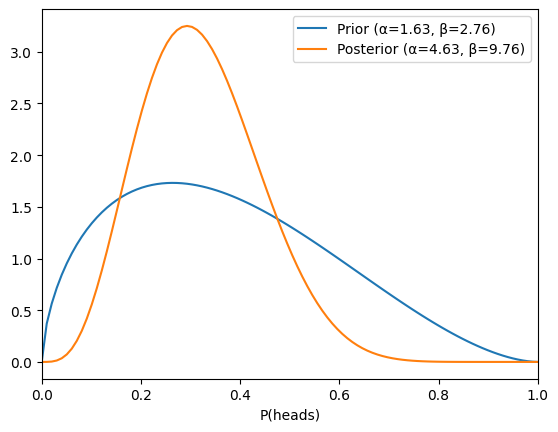

In [123]:
import numpy as np
import random 
import matplotlib.pyplot as plt
from scipy.stats import beta

agentalpha = 4* random.random()
agentbeta =  4* random.random()
x = np.linspace(0, 1., 100)

n = 10

def run(alphabelief, betabelief): 
    results = np.random.binomial(n=1, p=0.5,size=n)
    s = results.sum()

    # update. since bernoulli and beta are conjugates, it's just addition (p 25 Zollman, bottom paragraph) 
    posterior_alpha = alphabelief + s
    posterior_beta = betabelief + (n - s)
    return posterior_alpha, posterior_beta

posterior_alpha, posterior_beta = run(agentalpha,agentbeta)
plt.plot(x, beta.pdf(x, agentalpha, agentbeta), label=f"Prior (α={agentalpha:.2f}, β={agentbeta:.2f})")
plt.plot(x, beta.pdf(x, posterior_alpha, posterior_beta), label=f"Posterior (α={posterior_alpha:.2f}, β={posterior_beta:.2f})")
plt.xlim([0, 1])
plt.xlabel("P(heads)")
plt.legend()
plt.show()

Now we move to the full Figure 1 recreation. Here, we want 100 angents and 100 rounds and each round consists of 10 tosses. We take the mean as alpha/(alpha+beta) and calculate how far that is from the true mean (true_p) and average that across all the agents. Then, we plot that as a function of round. 

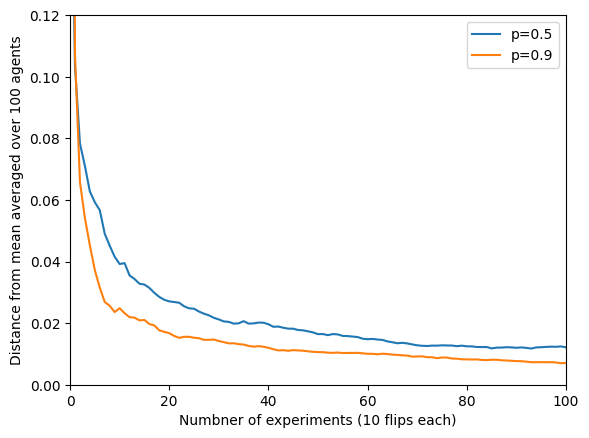

In [132]:
## recreating Fig 1. 
import numpy as np 
from scipy.stats import beta
import matplotlib.pyplot as plt

true_p = [0.5, 0.9]
total_rounds = 100 
tosses_per_round = 10
n_agents = 100

startalpa = 4* np.random.random(n_agents)
startbeta =  4* np.random.random(n_agents)

x = np.linspace(0, 1., 100)

def sim(true_p):
    agentalpha = startalpa
    agentbeta = startbeta
    alphas = [agentalpha]
    betas = [agentbeta]

    for _ in range (total_rounds): 
        # the numpy random "hides" another loop in the below that would otherwise iterate over each agent and each toss
        tosses = np.random.binomial(n=1, p=true_p, size=(n_agents, tosses_per_round))
        heads = tosses.sum(axis=1)

        # update. since bernoulli and beta are conjugates, it's just addition (p 25 Zollman, bottom paragraph) 
        agentalpha = agentalpha + heads
        agentbeta = agentbeta + tosses_per_round - heads
        alphas.append(agentalpha)
        betas.append(agentbeta)

    # switch to numpy arrays to make the calculations easier 
    alphas =np.array(alphas)
    betas =np.array(betas)
    means = alphas / (alphas + betas)
    distance = np.abs(means - true_p)

    plt.plot(distance.mean(axis=1), label=f"p={true_p}")
    plt.xlabel("Numbner of experiments (10 flips each)")
    plt.ylabel(f"Distance from mean averaged over {n_agents} agents")
    plt.xlim([0,100])
    plt.ylim([0,.12])
    plt.legend()

for p in true_p:
    sim(p)

plt.show()